In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# --- Load ---
df = pd.read_csv("data/uci-secom.csv", header=0)
df.columns = ["Time"] + [f"X{i}" for i in range(1, 591)] + ["Label"]
df["Time"] = pd.to_datetime(df["Time"])
df = df.sort_values("Time").reset_index(drop=True)

print(f"Shape: {df.shape}")
print(f"Fail rate: {(df['Label']==1).mean():.2%}")
print(f"Date range: {df['Time'].min()} → {df['Time'].max()}")

# --- Missing values ---
nan_counts = df.isnull().sum()
print(f"\nColumns with NaN: {nan_counts[nan_counts>0].shape[0]} / {df.shape[1]-2}")
print(f"Max NaN in any column: {nan_counts.max()}")

fig, ax = plt.subplots(figsize=(12, 3))
nan_counts[nan_counts > 0].plot(kind="bar", ax=ax)
ax.set_title("Missing values per feature")
ax.set_xlabel("Feature")
plt.tight_layout()
plt.savefig("data/missingness.png", dpi=100)
plt.show()

# --- Constant features ---
variances = df.iloc[:, 1:591].var()
constant_cols = variances[variances == 0].index
print(f"\nConstant features: {len(constant_cols)}")
df = df.drop(columns=constant_cols)
print(f"Shape after dropping constant: {df.shape}")

# --- Label distribution ---
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
df["Label"].value_counts().plot(kind="bar", ax=axes[0], color=["#2ecc71", "#e74c3c"])
axes[0].set_title("Pass/Fail distribution")
axes[0].set_xticklabels(["Pass (-1)", "Fail (+1)"], rotation=0)

df["fail_flag"] = (df["Label"] == 1).astype(int)
df.resample("D", on="Time")["fail_flag"].sum().plot(ax=axes[1], color="#e74c3c")
axes[1].set_title("Daily fail count")
plt.tight_layout()
plt.savefig("data/label_distribution.png", dpi=100)
plt.show()

# --- Impute NaNs ---
sensor_cols = [c for c in df.columns if c.startswith("X")]
df[sensor_cols] = df[sensor_cols].fillna(df[sensor_cols].median())

# --- Top 10 sensor distributions ---
top_var = df[sensor_cols].var().nlargest(10)
fig, axes = plt.subplots(2, 5, figsize=(16, 6))
for ax, (name, _) in zip(axes.flat, top_var.items()):
    df[name].plot(kind="hist", bins=40, ax=ax, edgecolor="black", alpha=0.7)
    ax.set_title(name, fontsize=9)
plt.suptitle("Top 10 sensors by variance", y=1.02)
plt.tight_layout()
plt.savefig("data/top_sensor_dists.png", dpi=100)
plt.show()

# --- Save cleaned data ---
df.to_csv("data/secom_cleaned.csv", index=False)
print("\n✅ Cleaned data saved to data/secom_cleaned.csv")   

FileNotFoundError: [Errno 2] No such file or directory: 'data/uci-secom.csv'

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# --- Load ---
df = pd.read_csv("C:/Users/sharanu.ganji/secom-yield-dashboard/data/uci-secom.csv", header=0)   
df.columns = ["Time"] + [f"X{i}" for i in range(1, 591)] + ["Label"]
df["Time"] = pd.to_datetime(df["Time"])
df = df.sort_values("Time").reset_index(drop=True)

print(f"Shape: {df.shape}")
print(f"Fail rate: {(df['Label']==1).mean():.2%}")
print(f"Date range: {df['Time'].min()} → {df['Time'].max()}")

# --- Missing values ---
nan_counts = df.isnull().sum()
print(f"\nColumns with NaN: {nan_counts[nan_counts>0].shape[0]} / {df.shape[1]-2}")
print(f"Max NaN in any column: {nan_counts.max()}")

fig, ax = plt.subplots(figsize=(12, 3))
nan_counts[nan_counts > 0].plot(kind="bar", ax=ax)
ax.set_title("Missing values per feature")
ax.set_xlabel("Feature")
plt.tight_layout()
plt.savefig("data/missingness.png", dpi=100)
plt.show()

# --- Constant features ---
variances = df.iloc[:, 1:591].var()
constant_cols = variances[variances == 0].index
print(f"\nConstant features: {len(constant_cols)}")
df = df.drop(columns=constant_cols)
print(f"Shape after dropping constant: {df.shape}")

# --- Label distribution ---
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
df["Label"].value_counts().plot(kind="bar", ax=axes[0], color=["#2ecc71", "#e74c3c"])
axes[0].set_title("Pass/Fail distribution")
axes[0].set_xticklabels(["Pass (-1)", "Fail (+1)"], rotation=0)

df["fail_flag"] = (df["Label"] == 1).astype(int)
df.resample("D", on="Time")["fail_flag"].sum().plot(ax=axes[1], color="#e74c3c")
axes[1].set_title("Daily fail count")
plt.tight_layout()
plt.savefig("data/label_distribution.png", dpi=100)
plt.show()

# --- Impute NaNs ---
sensor_cols = [c for c in df.columns if c.startswith("X")]
df[sensor_cols] = df[sensor_cols].fillna(df[sensor_cols].median())

# --- Top 10 sensor distributions ---
top_var = df[sensor_cols].var().nlargest(10)
fig, axes = plt.subplots(2, 5, figsize=(16, 6))
for ax, (name, _) in zip(axes.flat, top_var.items()):
    df[name].plot(kind="hist", bins=40, ax=ax, edgecolor="black", alpha=0.7)
    ax.set_title(name, fontsize=9)
plt.suptitle("Top 10 sensors by variance", y=1.02)
plt.tight_layout()
plt.savefig("data/top_sensor_dists.png", dpi=100)
plt.show()

# --- Save cleaned data ---
df.to_csv("data/secom_cleaned.csv", index=False)
print("\n✅ Cleaned data saved to data/secom_cleaned.csv")   

FileNotFoundError: [Errno 2] No such file or directory: 'data/uci-secom.csv'

Shape: (1567, 592)
Fail rate: 6.64%
Date range: 2008-01-08 02:02:00 → 2008-12-10 18:47:00

Columns with NaN: 538 / 590
Max NaN in any column: 1429


FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\sharanu.ganji\\secom-yield-dashboard\\notebooks\\data\\missingness.png'

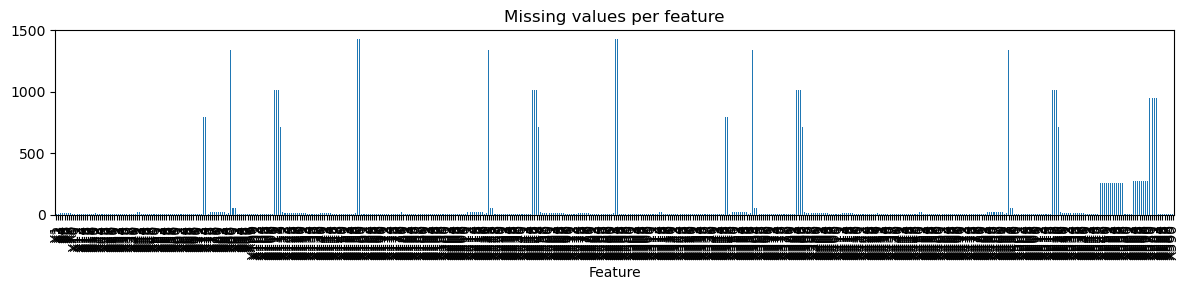

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# --- Load ---
df = pd.read_csv("C:/Users/sharanu.ganji/secom-yield-dashboard/data/uci-secom.csv", header=0)   
df.columns = ["Time"] + [f"X{i}" for i in range(1, 591)] + ["Label"]
df["Time"] = pd.to_datetime(df["Time"])
df = df.sort_values("Time").reset_index(drop=True)

print(f"Shape: {df.shape}")
print(f"Fail rate: {(df['Label']==1).mean():.2%}")
print(f"Date range: {df['Time'].min()} → {df['Time'].max()}")

# --- Missing values ---
nan_counts = df.isnull().sum()
print(f"\nColumns with NaN: {nan_counts[nan_counts>0].shape[0]} / {df.shape[1]-2}")
print(f"Max NaN in any column: {nan_counts.max()}")

fig, ax = plt.subplots(figsize=(12, 3))
nan_counts[nan_counts > 0].plot(kind="bar", ax=ax)
ax.set_title("Missing values per feature")
ax.set_xlabel("Feature")
plt.tight_layout()
plt.savefig("data/missingness.png", dpi=100)
plt.show()

# --- Constant features ---
variances = df.iloc[:, 1:591].var()
constant_cols = variances[variances == 0].index
print(f"\nConstant features: {len(constant_cols)}")
df = df.drop(columns=constant_cols)
print(f"Shape after dropping constant: {df.shape}")

# --- Label distribution ---
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
df["Label"].value_counts().plot(kind="bar", ax=axes[0], color=["#2ecc71", "#e74c3c"])
axes[0].set_title("Pass/Fail distribution")
axes[0].set_xticklabels(["Pass (-1)", "Fail (+1)"], rotation=0)

df["fail_flag"] = (df["Label"] == 1).astype(int)
df.resample("D", on="Time")["fail_flag"].sum().plot(ax=axes[1], color="#e74c3c")
axes[1].set_title("Daily fail count")
plt.tight_layout()
plt.savefig("data/label_distribution.png", dpi=100)
plt.show()

# --- Impute NaNs ---
sensor_cols = [c for c in df.columns if c.startswith("X")]
df[sensor_cols] = df[sensor_cols].fillna(df[sensor_cols].median())

# --- Top 10 sensor distributions ---
top_var = df[sensor_cols].var().nlargest(10)
fig, axes = plt.subplots(2, 5, figsize=(16, 6))
for ax, (name, _) in zip(axes.flat, top_var.items()):
    df[name].plot(kind="hist", bins=40, ax=ax, edgecolor="black", alpha=0.7)
    ax.set_title(name, fontsize=9)
plt.suptitle("Top 10 sensors by variance", y=1.02)
plt.tight_layout()
plt.savefig("data/top_sensor_dists.png", dpi=100)
plt.show()

# --- Save cleaned data ---
df.to_csv("data/secom_cleaned.csv", index=False)
print("\n✅ Cleaned data saved to data/secom_cleaned.csv")   

Shape: (1567, 592)
Fail rate: 6.64%
Date range: 2008-01-08 02:02:00 → 2008-12-10 18:47:00

Columns with NaN: 538 / 590
Max NaN in any column: 1429


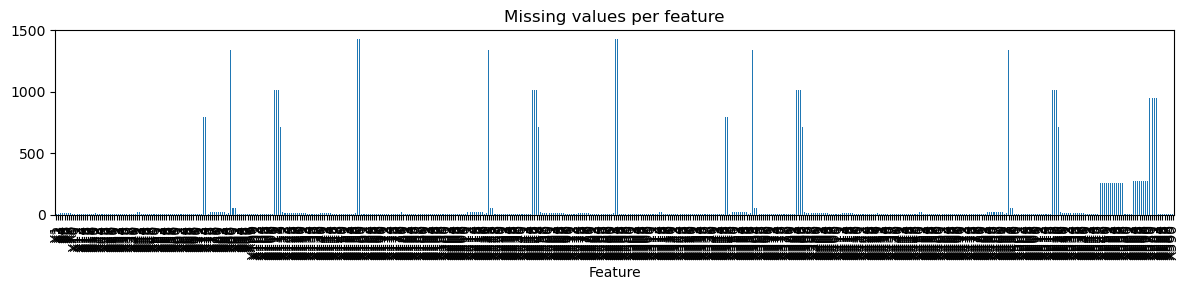


Constant features: 116
Shape after dropping constant: (1567, 476)


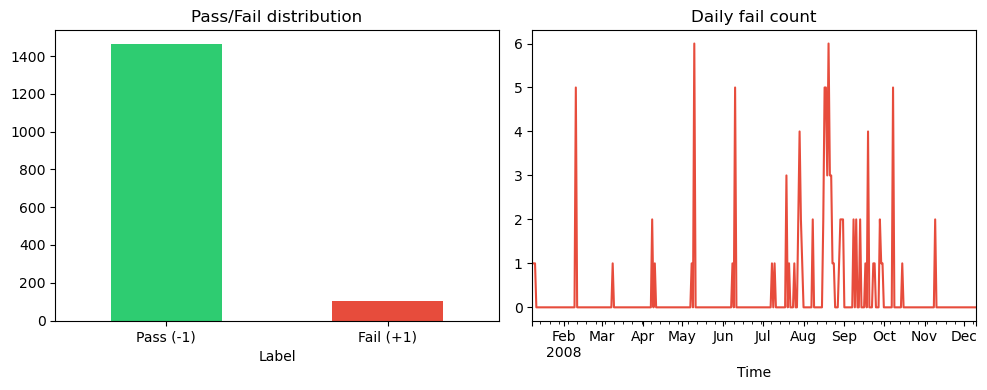

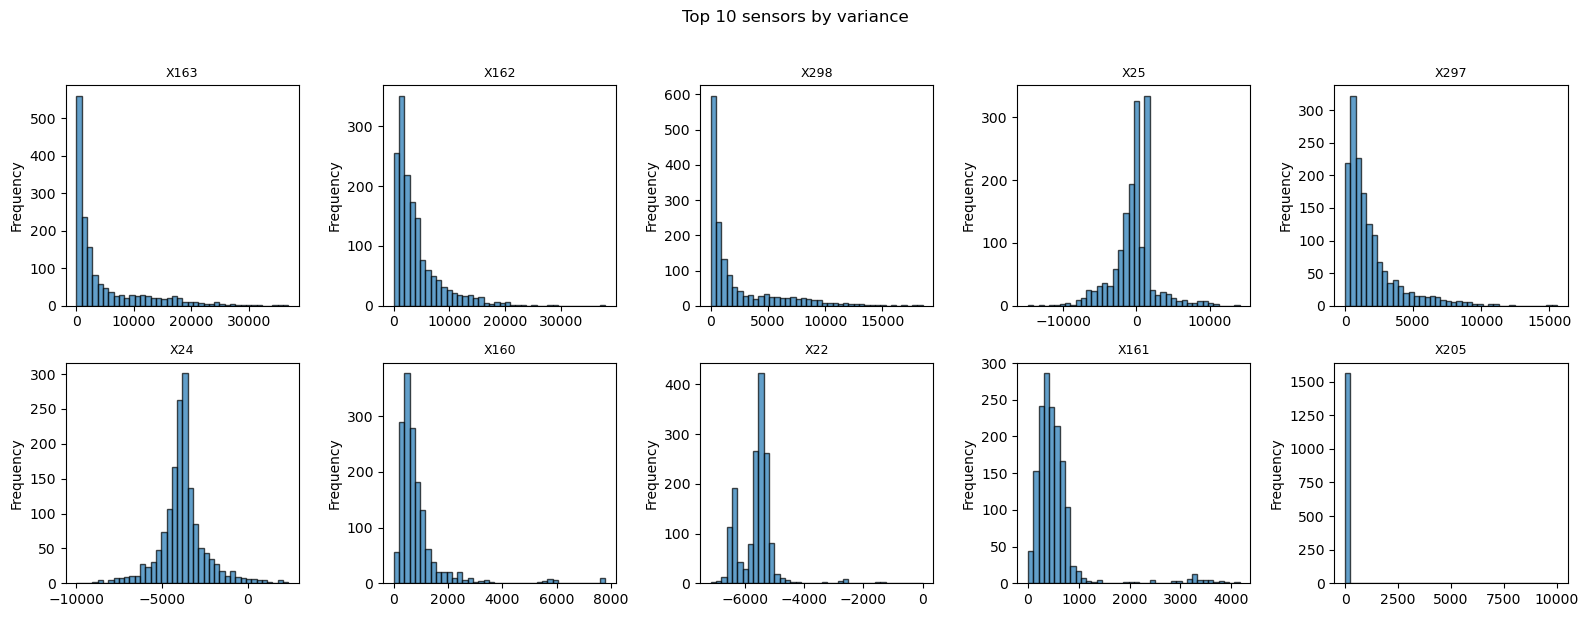


✅ Cleaned data saved to C:/Users/sharanu.ganji/secom-yield-dashboard/data\secom_cleaned.csv


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# --- Paths ---
DATA_DIR = "C:/Users/sharanu.ganji/secom-yield-dashboard/data"
os.makedirs(DATA_DIR, exist_ok=True)

# --- Load ---
df = pd.read_csv(os.path.join(DATA_DIR, "uci-secom.csv"), header=0)
df.columns = ["Time"] + [f"X{i}" for i in range(1, 591)] + ["Label"]
df["Time"] = pd.to_datetime(df["Time"])
df = df.sort_values("Time").reset_index(drop=True)

print(f"Shape: {df.shape}")
print(f"Fail rate: {(df['Label']==1).mean():.2%}")
print(f"Date range: {df['Time'].min()} → {df['Time'].max()}")

# --- Missing values ---
nan_counts = df.isnull().sum()
print(f"\nColumns with NaN: {nan_counts[nan_counts>0].shape[0]} / {df.shape[1]-2}")
print(f"Max NaN in any column: {nan_counts.max()}")

fig, ax = plt.subplots(figsize=(12, 3))
nan_counts[nan_counts > 0].plot(kind="bar", ax=ax)
ax.set_title("Missing values per feature")
ax.set_xlabel("Feature")
plt.tight_layout()
plt.savefig(os.path.join(DATA_DIR, "missingness.png"), dpi=100)
plt.show()

# --- Constant features ---
variances = df.iloc[:, 1:591].var()
constant_cols = variances[variances == 0].index
print(f"\nConstant features: {len(constant_cols)}")
df = df.drop(columns=constant_cols)
print(f"Shape after dropping constant: {df.shape}")

# --- Label distribution ---
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
df["Label"].value_counts().plot(kind="bar", ax=axes[0], color=["#2ecc71", "#e74c3c"])
axes[0].set_title("Pass/Fail distribution")
axes[0].set_xticklabels(["Pass (-1)", "Fail (+1)"], rotation=0)

df["fail_flag"] = (df["Label"] == 1).astype(int)
df.resample("D", on="Time")["fail_flag"].sum().plot(ax=axes[1], color="#e74c3c")
axes[1].set_title("Daily fail count")
plt.tight_layout()
plt.savefig(os.path.join(DATA_DIR, "label_distribution.png"), dpi=100)
plt.show()

# --- Impute NaNs ---
sensor_cols = [c for c in df.columns if c.startswith("X")]
df[sensor_cols] = df[sensor_cols].fillna(df[sensor_cols].median())

# --- Top 10 sensor distributions ---
top_var = df[sensor_cols].var().nlargest(10)
fig, axes = plt.subplots(2, 5, figsize=(16, 6))
for ax, (name, _) in zip(axes.flat, top_var.items()):
    df[name].plot(kind="hist", bins=40, ax=ax, edgecolor="black", alpha=0.7)
    ax.set_title(name, fontsize=9)
plt.suptitle("Top 10 sensors by variance", y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(DATA_DIR, "top_sensor_dists.png"), dpi=100)
plt.show()

# --- Save cleaned data ---
df.to_csv(os.path.join(DATA_DIR, "secom_cleaned.csv"), index=False)
print(f"\n✅ Cleaned data saved to {os.path.join(DATA_DIR, 'secom_cleaned.csv')}")   